# Finding Cointegrated Semiconductor Pairs for Pairs Trading

Following an initial study of CVX and XOM, we look for companies that may exhibit a more stable cointegrating relationship. We focus on the semiconductor industry and follow these steps:

1. Select an industry based on a hypothesis of shared economic and business drivers.
2. Download dividend- and split-adjusted stock prices.
3. Examine correlations in daily log returns to identify related stocks.
4. Apply the Augmented Dickey–Fuller (ADF) and Engle–Granger tests to assess integration of order one, $I(1)$, and cointegration in log prices.
5. Examine cointegration across rolling windows and estimate the speed of spread mean reversion.
6. Rank and select candidate pairs, then evaluate a rule-based strategy out of sample.

**Sample design:** model estimation uses 2021–2024 data (*in-sample*, IS); the trading backtest starts in January 2025 (*out-of-sample*, OOS). The data download uses the current date as its end date, so a fresh run may differ from the saved results.

In [1]:
# Imports
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import datetime
import seaborn as sns

import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.stattools import coint
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

from itertools import combinations

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Download adjusted prices for semiconductor-related stocks
tickers = [
    "NVDA", "AMD", "INTC", "QCOM", "AVGO", "MRVL",
    "TXN", "ADI", "NXPI", "MCHP", "ON", "MPWR", "STM",
    "AMAT", "LRCX", "KLAC", "TER", "ONTO", "ENTG", "MKSI",
    "CDNS", "SNPS",
    "TSM", "GFS", "TSEM"
]
start_date = datetime.datetime(2021, 1, 1)
end_date = datetime.date.today()

print("--- Downloading Yahoo Finance data ---")
try:
    data = yf.download(
            tickers,
            start = start_date,
            end = end_date,
            auto_adjust=True # Adjust historical prices for dividends and splits; used later in the backtest
        )
except Exception as e:
    print("Data download failed")
    print(e)


--- Downloading Yahoo Finance data ---


[*********************100%***********************]  25 of 25 completed


We normalize adjusted stock prices to a base of 100. This removes differences in their starting price levels and makes relative price movements easier to compare:

$$
P_t^{\mathrm{Norm}}=\frac{P_t}{P_0}\times100
$$

Here $P_0$ is each stock's first available observation.

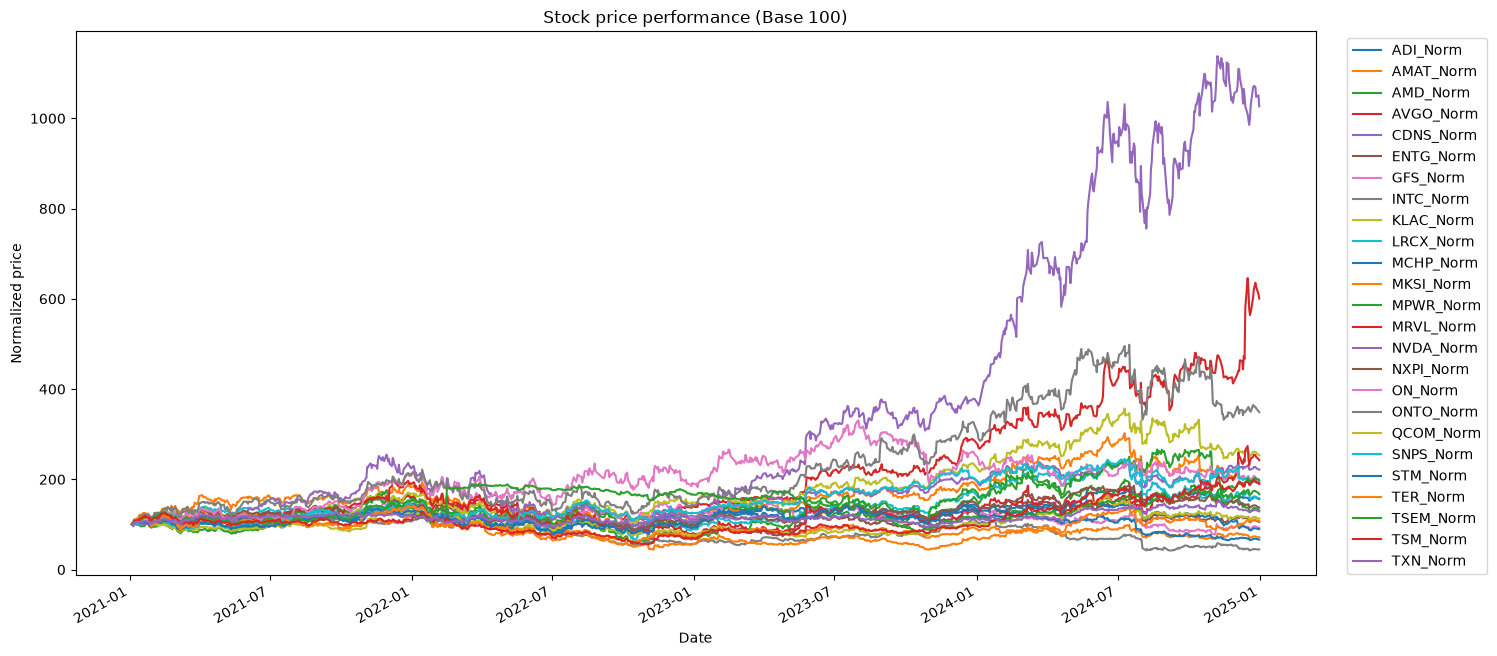

In [3]:
# Clean and plot prices normalized to a base of 100
col = "Adj Close" if "Adj Close" in data.columns else "Close"
data = data[col]

# Normalize each series to a base of 100
def normalizar_columna(col, base=100):
    return col * base / col.dropna().iloc[0]

data_norm = data.apply(normalizar_columna).add_suffix("_Norm")

fecha_limite = datetime.datetime(2025, 1, 1)
data_norm_train = data_norm[data_norm.index < fecha_limite]

# Plot the training data
data_norm_train.plot(figsize=(16,8))
plt.title("Stock price performance (Base 100)")
plt.ylabel("Normalized price")
plt.legend(bbox_to_anchor=(1.02, 1), loc = "upper left")
plt.show()

In [4]:
# Review sample coverage and descriptive statistics
print("Sample shape", data_norm_train.shape)
print("First date", data_norm_train.index.min())
print("Last date", data_norm_train.index.max())


data_norm_train.describe()

Sample shape (1005, 25)
First date 2021-01-04 00:00:00
Last date 2024-12-31 00:00:00


Ticker,ADI_Norm,AMAT_Norm,AMD_Norm,AVGO_Norm,CDNS_Norm,ENTG_Norm,GFS_Norm,INTC_Norm,KLAC_Norm,LRCX_Norm,...,NXPI_Norm,ON_Norm,ONTO_Norm,QCOM_Norm,SNPS_Norm,STM_Norm,TER_Norm,TSEM_Norm,TSM_Norm,TXN_Norm
count,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,798.000000,1005.000000,1005.000000,1005.000000,...,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000
mean,127.684312,167.114807,122.669800,210.450856,151.410514,115.345879,118.562059,84.379169,182.894805,136.537335,...,128.882604,200.409381,233.853048,101.110811,154.882808,106.463837,95.681285,143.349101,107.758079,116.011476
std,19.688823,44.973000,35.817597,117.777803,44.464229,20.898555,16.748354,23.447476,65.694883,36.499220,...,21.470694,50.573259,106.290489,18.577068,43.290508,17.412585,16.255231,29.247476,32.138922,10.906657
min,96.571352,86.854042,60.606714,99.066366,88.155572,66.305403,77.607760,42.068515,100.000000,67.183663,...,87.480350,100.000000,100.000000,72.319532,85.783278,65.099457,60.253575,84.269230,55.694122,94.015204
25%,112.818886,133.513642,93.835317,121.948500,112.146439,101.726276,108.367457,65.003960,130.520205,108.683733,...,112.619923,166.819722,151.350225,86.992732,119.375733,95.797840,84.666786,114.999999,84.676213,108.501350
50%,123.446231,158.467355,115.525454,149.581660,136.733951,115.329979,119.342675,80.028521,154.385227,130.537938,...,125.228187,207.162547,181.892398,95.945985,141.743225,107.999648,93.080466,145.884617,101.131686,114.811064
75%,138.399360,189.349228,150.487529,283.849095,193.687406,129.175399,129.364225,104.555181,227.376557,158.977072,...,142.378017,231.435583,311.032029,115.685382,196.069894,119.420201,106.494199,169.076920,116.719668,119.801098
max,177.446601,302.160237,229.014082,645.958155,240.497947,162.990879,170.129324,138.261195,357.042494,245.292996,...,190.491953,330.854002,498.304356,164.864230,243.934038,142.859381,141.843783,203.576924,199.196164,151.606241


We compute log prices and daily log returns, then calculate their Pearson correlation matrix to identify stocks with similar daily movements. For two return series $X$ and $Y$:

$$
\rho_{X,Y}=\frac{\operatorname{Cov}(X,Y)}{\sigma_X\sigma_Y}
$$

Correlation lies between $-1$ and $1$:
- Near $1$: returns tend to move in the same direction.
- Near $0$: little linear association.
- Near $-1$: returns tend to move in opposite directions.

**Correlation alone does not establish cointegration**; the two concepts test different properties.

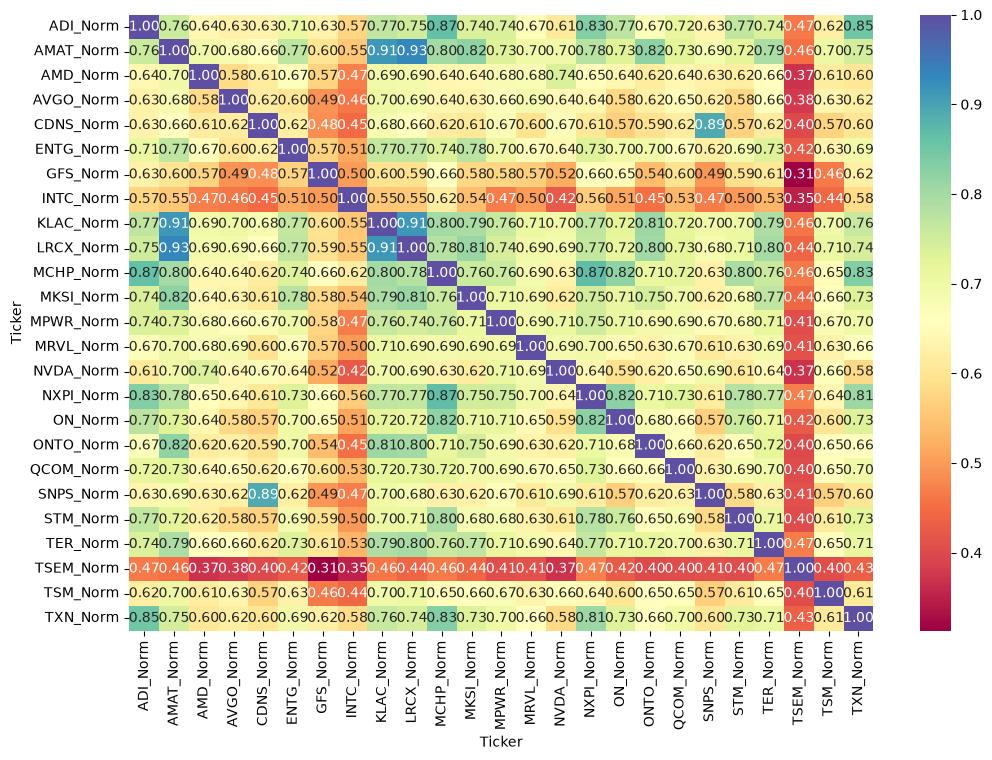

In [5]:
# Compute log prices and daily log returns
data_norm_train_logs = np.log(data_norm_train)
data_norm_train_logs_diff = data_norm_train_logs.diff()

# Compute the Pearson correlation matrix for daily log returns
matriz_corr = data_norm_train_logs_diff.corr()
plt.figure(figsize=(12,8))
sns.heatmap(matriz_corr, annot = True, cmap = "Spectral", fmt = ".2f")
plt.show()

Several high-correlation pairs stand out:

- AMAT–LRCX: $0.93$
- AMAT–KLAC: $0.91$
- KLAC–LRCX: $0.91$
- CDNS–SNPS: $0.89$
- ADI–MCHP: $0.87$
- MCHP–NXPI: $0.87$
- ADI–TXN: $0.85$

AMAT–LRCX, AMAT–KLAC, KLAC–LRCX, and CDNS–SNPS are particularly interesting because the companies also operate in closely related business segments.

In [6]:
# Extract the ten most correlated pairs
# Exclude the diagonal and lower triangle of the matrix
mascara = np.triu(np.ones(matriz_corr.shape, dtype=bool), k=1)
matriz_corr_sup = matriz_corr.where(mascara)
pares = matriz_corr_sup.stack()
print(pares.sort_values(ascending = False).head(10))

Ticker     Ticker   
AMAT_Norm  LRCX_Norm    0.930370
           KLAC_Norm    0.914036
KLAC_Norm  LRCX_Norm    0.912165
CDNS_Norm  SNPS_Norm    0.890659
MCHP_Norm  NXPI_Norm    0.867513
ADI_Norm   MCHP_Norm    0.865395
           TXN_Norm     0.851219
           NXPI_Norm    0.833106
MCHP_Norm  TXN_Norm     0.832020
NXPI_Norm  ON_Norm      0.823809
dtype: float64


Three groups stand out:

- **Semiconductor equipment:** AMAT–LRCX ($0.9304$), AMAT–KLAC ($0.9140$), and KLAC–LRCX ($0.9122$).
- **Electronic design automation:** CDNS–SNPS ($0.8907$).
- **Analog and related semiconductor companies:** MCHP–NXPI ($0.8675$), ADI–MCHP ($0.8654$), among others.

Highly correlated stocks often belong to the same subsector. Before testing for cointegration, we check whether the log-price series are consistent with being integrated of order one:

$$
\ln(P_t)\sim I(1)
$$

That means log prices have a unit root, while their first differences are stationary. We use the ADF test:

- $H_0$: the series has a unit root.
- $H_1$: the series is stationary around the deterministic terms included in the test.

The test results provide evidence *consistent* with $I(1)$; failing to reject a unit root is not proof that one exists.

In [7]:
# Apply ADF unit-root tests to the initial candidate pair
def estudiar_propiedad_I1(x, y, tendencia = "c"):
    '''
    Run ADF tests for the two input series (I(1) screening).
    x: first time series
    y: second time series
    tendencia: ADF deterministic specification; "c" includes a constant
    '''

    adf_results_x = adfuller(x, regression=tendencia)
    adf_results_y = adfuller(y, regression=tendencia)

    print(f"ADF {x.name}: {adf_results_x[1]:.4f} (p-value)")
    print(f"ADF {y.name}: {adf_results_y[1]:.4f} (p-value)")


# Test both log-price levels and first differences for AMAT-LRCX
x_log = data_norm_train_logs["AMAT_Norm"]
y_log = data_norm_train_logs["LRCX_Norm"]

x_log_diff = data_norm_train_logs_diff["AMAT_Norm"].dropna()
y_log_diff = data_norm_train_logs_diff["LRCX_Norm"].dropna()

print("--- ADF tests: log-price levels ---")
estudiar_propiedad_I1(x_log, y_log)
print("\n--- ADF tests: daily log returns ---")
estudiar_propiedad_I1(x_log_diff, y_log_diff)

--- ADF tests: log-price levels ---
ADF AMAT_Norm: 0.3064 (p-value)
ADF LRCX_Norm: 0.4448 (p-value)

--- ADF tests: daily log returns ---
ADF AMAT_Norm: 0.0000 (p-value)
ADF LRCX_Norm: 0.0000 (p-value)


The ADF results are consistent with both log-price series being $I(1)$:

- **Log prices:** the unit-root null is not rejected.
- **First differences (log returns):** the unit-root null is rejected.

### Engle–Granger cointegration test

We test whether a stationary linear combination exists between AMAT and LRCX log prices. In the regression actually estimated below, **LRCX is the dependent variable** and AMAT is the explanatory variable:

$$
\ln(P_{LRCX,t})=\alpha+\beta\ln(P_{AMAT,t})+\varepsilon_t
$$

If the residual process $\varepsilon_t$ is stationary, this supports cointegration.

- $H_0$: no cointegration.
- $H_1$: cointegration.

In [8]:
# Run the Engle-Granger cointegration test
def egen_granger(x, y):
    resultado = coint(y, x)
    print("--- Engle-Granger results ---")
    print(f"Test statistic: {resultado[0]:.4f}")
    print(f"p-value: {resultado[1]:.4f}")
    print(f"Critical values: {resultado[2]}")

egen_granger(x_log, y_log)

--- Engle-Granger results ---
Test statistic: -3.3977
p-value: 0.0426
Critical values: [-3.90738153 -3.34222253 -3.048677  ]


The Engle–Granger test produces $p=0.0426$ for AMAT–LRCX. At the unadjusted $5\%$ level, we reject the null of no cointegration. This is initial evidence of a long-run linear relationship, **before adjusting for the fact that multiple candidate pairs are being tested**.

We estimate the corresponding spread from the regression:

$$
\ln(P_{LRCX,t})=\alpha+\beta\ln(P_{AMAT,t})+\varepsilon_t
$$

                            OLS Regression Results                            
Dep. Variable:              LRCX_Norm   R-squared:                       0.951
Model:                            OLS   Adj. R-squared:                  0.951
Method:                 Least Squares   F-statistic:                 1.933e+04
Date:               lu., 19 oct. 2026   Prob (F-statistic):               0.00
Time:                        13:55:03   Log-Likelihood:                 1444.9
No. Observations:                1005   AIC:                            -2886.
Df Residuals:                    1003   BIC:                            -2876.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0508      0.036     -1.430      0.1

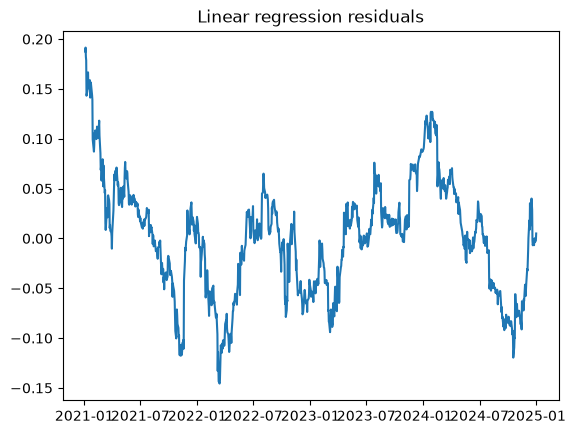

In [9]:
# Estimate the OLS cointegrating relationship
x_log_const = sm.add_constant(x_log)
modelo = sm.OLS(y_log, x_log_const).fit()
print(modelo.summary())

# Inspect the regression residuals
resid = modelo.resid
plt.figure()
plt.plot(resid)
plt.title("Linear regression residuals")
plt.show()

The estimated ordinary least squares (OLS) relationship is:

$$
\ln(P_{LRCX,t})=\alpha+\beta\ln(P_{AMAT,t})+\varepsilon_t
$$

Using normalized prices, the estimates are:

$$
\ln(P_{LRCX,t})=-0.0508+0.9703\ln(P_{AMAT,t})+\varepsilon_t
$$

with $R^2=0.951$. This indicates a strong in-sample linear fit, but a high $R^2$ alone does not demonstrate cointegration.

The spread is the regression residual:

$$
S_t=\ln(P_{LRCX,t})-\alpha-\beta\ln(P_{AMAT,t})
$$

The residual plot fluctuates around zero but displays prolonged deviations. The Durbin–Watson statistic is approximately $DW=0.032$, suggesting substantial positive serial correlation in the residuals.

AMAT and LRCX therefore merit further examination, but their suitability for trading is not yet established. Next, we inspect the residual ACF/PACF and fit an autoregressive model to quantify the speed of mean reversion.

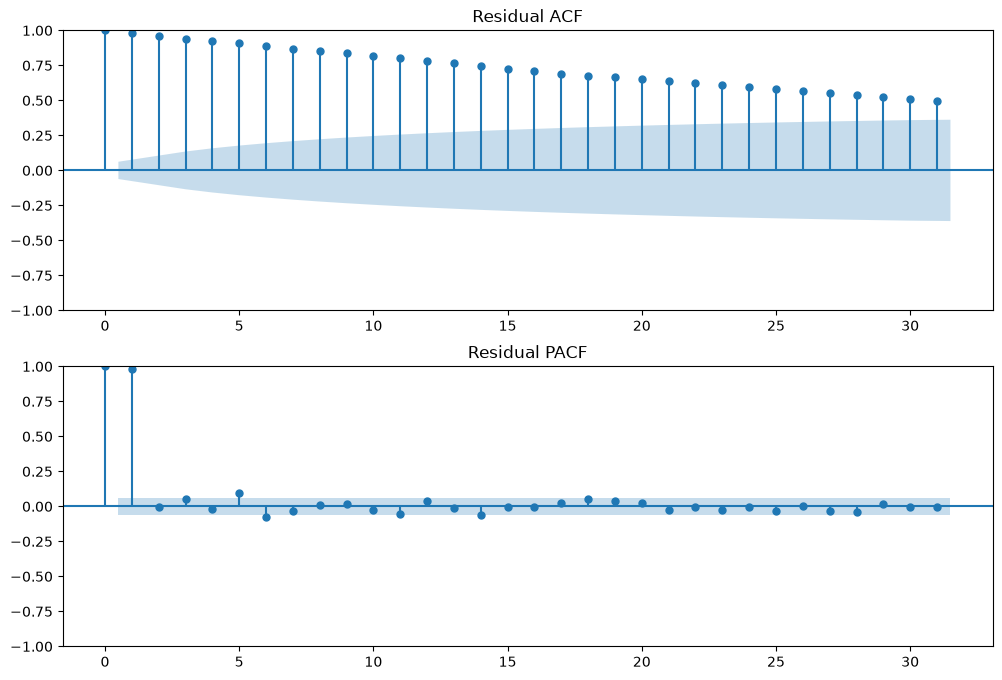

In [10]:
# Plot the residual ACF and PACF
fig, ax = plt.subplots(2, 1, figsize = (12,8))
plot_acf(resid, ax = ax[0], title = "Residual ACF")
plot_pacf(resid, ax = ax[1], title = "Residual PACF")
plt.show()

In [11]:
# Inspect residual persistence with a BIC-selected ARIMA model
def ajustar_arima_optimo(serie, p_max, d_max, q_max, alpha = 0.05):
    """
    Fit candidate ARIMA(p,d,q) models and select the one with the lowest BIC.

    Parameters:
    serie: array-like; time series to model
    p_max: int; highest autoregressive order considered
    d_max: int; highest differencing order allowed
    q_max: int; highest moving-average order considered
    alpha: float; ADF significance level used to select differencing

    Returns:
    best_model: fitted ARIMAResults instance with the lowest BIC
    """
    serie = np.asarray(serie)
    d = 0
    serie_diff = serie.copy()

    # Use the ADF test to determine the order of differencing
    while d <= d_max:
        adf_result  = adfuller(serie_diff)
        p_value = adf_result[1]

        if p_value < alpha:
            break

        serie_diff = np.diff(serie_diff)
        d += 1

    if d > d_max:
        raise ValueError("Stationarity was not achieved within the allowed d_max.")

    # Search for p and q using the Bayesian information criterion
    best_bic = np.inf
    best_model = None
    best_order = None

    for p in range(p_max + 1):
        for q in range(q_max + 1):
            try:
                model = ARIMA(serie, order=(p, d, q))
                model_fit = model.fit()
                print(f"ARIMA model ({p},{d},{q}) - BIC: {model_fit.bic}")

                if model_fit.bic < best_bic:
                    best_bic = model_fit.bic
                    best_model = model_fit
                    best_order = (p, d, q)

            except Exception as e:
                print(f"Error fitting ARIMA({p},{d},{q}): {e}")
                continue

    print(f"Best ARIMA model {best_order} - BIC: {best_bic:.4f}")
    return best_model


ar_modelo = ajustar_arima_optimo(resid, 3, 0, 3)
print(ar_modelo.summary())

ARIMA model (0,0,0) - BIC: -2876.0002318967204
ARIMA model (0,0,1) - BIC: -4040.328227132087
ARIMA model (0,0,2) - BIC: -4707.31489721677
ARIMA model (0,0,3) - BIC: -5190.712524414878
ARIMA model (1,0,0) - BIC: -6330.58934873712
ARIMA model (1,0,1) - BIC: -6323.627389417874
ARIMA model (1,0,2) - BIC: -6321.276129857443
ARIMA model (1,0,3) - BIC: -6315.329922382787
ARIMA model (2,0,0) - BIC: -6323.423997058523
ARIMA model (2,0,1) - BIC: -6323.415088510451
ARIMA model (2,0,2) - BIC: -6318.80578361917
ARIMA model (2,0,3) - BIC: -6314.558967173202
ARIMA model (3,0,0) - BIC: -6319.897127749008
ARIMA model (3,0,1) - BIC: -6314.908456444959
ARIMA model (3,0,2) - BIC: -6316.733060734064
ARIMA model (3,0,3) - BIC: -6307.85666668289
Best ARIMA model (1, 0, 0) - BIC: -6330.5893
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1005
Model:                 ARIMA(1, 0, 0)   Log Likelihood          

The selected residual model is approximately AR(1):

$$
w_t=0.9788w_{t-1}+\varepsilon_t
$$

- Because $|\phi|<1$, the fitted AR(1) is stationary under its assumed specification.
- Since $\phi$ is close to one, deviations from equilibrium are persistent.
- The expected deviation declines by roughly $1-\phi\approx2.1\%$ per trading session.

For an AR(1) process with $0<\phi<1$, the half-life of an expected deviation is:

$$
HL=\frac{\ln(0.5)}{\ln(\phi)}
$$

Substituting the fitted coefficient:

$$
HL=\frac{\ln(0.5)}{\ln(0.9788)}\approx\boxed{32.35\text{ trading sessions}}
$$

This is the approximate time for the *expected residual deviation* to halve; it is **not** a prediction of when a particular trade will close.

For a pairs-trading strategy, the findings are mixed:

- The unadjusted Engle–Granger test suggests cointegration ($p=0.0426$).
- The estimated reversion is relatively slow.
- Trades may remain open for several weeks, increasing risk and financing costs.

We next check cointegration stability across subperiods. Multiple-testing concerns also warrant caution when interpreting the initial $p$-value.

   Inicio  Final   P-value      Beta
0    2021   2022  0.110315  0.904521
1    2022   2023  0.553125  1.035857
2    2023   2024  0.498319  0.985495


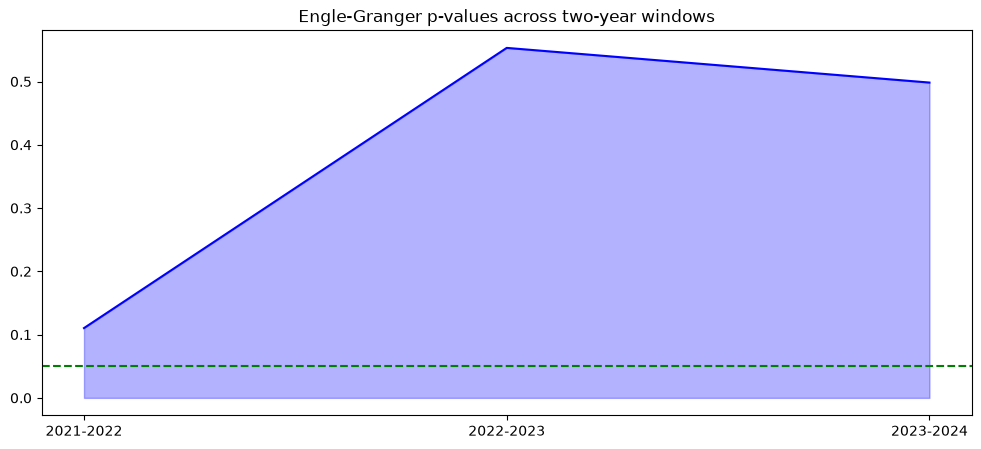

In [12]:
resultados = []

for i in range(2021, 2024):
    fin = i + 1
    ventana = data_norm_train_logs.loc[f"{i}-01-01":f"{fin}-12-31"]

    x_t = ventana['AMAT_Norm']
    y_t = ventana['LRCX_Norm']

    resultado = coint(
        y_t,
        x_t
    )

    p_value = resultado[1]

    modelo = sm.OLS(y_t, sm.add_constant(x_t)).fit()
    b = modelo.params["AMAT_Norm"]

    resultados.append({
        "Inicio": i,
        "Final": fin,
        "P-value": resultado[1],
        "Beta": b
    })


df_resultado = pd.DataFrame(resultados)
print(df_resultado.head())

# Visualize p-values relative to the 5% rejection threshold
df_resultado['Periodo'] = df_resultado["Inicio"].astype(str) + "-" + df_resultado["Final"].astype(str)
plt.figure(figsize = (12,5))
plt.plot(df_resultado['Periodo'], df_resultado["P-value"], color = "blue")
plt.fill_between(df_resultado['Periodo'], df_resultado["P-value"], color="blue", alpha = 0.3)
plt.axhline(y = 0.05, color="green", linestyle = "--")
plt.title("Engle-Granger p-values across two-year windows")
plt.show()

None of the two-year windows rejects the null hypothesis of no cointegration for AMAT–LRCX at the $5\%$ level. This does not prove the absence of cointegration: shorter samples may reduce test power. Nevertheless, the lack of stability is a warning sign. We do not exclude the pair permanently, but we refrain from selecting it for trading at this stage. Next, we apply Engle–Granger to the remaining highly correlated candidate pairs.

In [13]:
df_parejas = (
    pares.sort_values(ascending=False)
    .head(10)
    .rename_axis(["X", "Y"])
    .reset_index(name="Correlacion")
)

for fila in df_parejas.itertuples(index=False):
    x_log = data_norm_train_logs[fila.X]
    y_log = data_norm_train_logs[fila.Y]

    pareja = f"{fila.X.replace('_Norm', '')} - {fila.Y.replace('_Norm', '')}"

    print("\n" + "=" * 45)
    print(f"Pair: {pareja} | Correlation: {fila.Correlacion:.4f}")
    print("=" * 45)

    egen_granger(x_log, y_log)


Pair: AMAT - LRCX | Correlation: 0.9304
--- Engle-Granger results ---
Test statistic: -3.3977
p-value: 0.0426
Critical values: [-3.90738153 -3.34222253 -3.048677  ]

Pair: AMAT - KLAC | Correlation: 0.9140
--- Engle-Granger results ---
Test statistic: -0.9026
p-value: 0.9198
Critical values: [-3.90738153 -3.34222253 -3.048677  ]

Pair: KLAC - LRCX | Correlation: 0.9122
--- Engle-Granger results ---
Test statistic: -1.6520
p-value: 0.6985
Critical values: [-3.90738153 -3.34222253 -3.048677  ]

Pair: CDNS - SNPS | Correlation: 0.8907
--- Engle-Granger results ---
Test statistic: -2.9740
p-value: 0.1165
Critical values: [-3.90738153 -3.34222253 -3.048677  ]

Pair: MCHP - NXPI | Correlation: 0.8675
--- Engle-Granger results ---
Test statistic: -0.7107
p-value: 0.9455
Critical values: [-3.90738153 -3.34222253 -3.048677  ]

Pair: ADI - MCHP | Correlation: 0.8654
--- Engle-Granger results ---
Test statistic: -1.1174
p-value: 0.8782
Critical values: [-3.90738153 -3.34222253 -3.048677  ]

Pair

Among the ten highest-correlation pairs, only AMAT–LRCX passes an *unadjusted* $5\%$ Engle–Granger test. However, applying the Bonferroni correction for these ten comparisons gives a threshold of $0.05/10=0.005$, so none qualifies. We therefore broaden the screen to all eligible pairs rather than relying on correlation alone.

In [14]:
# Check whether each log-price series is consistent with I(1)
def estudiar_propiedad_I1(serie_log, serie_diff, tendencia="c", alpha=0.05):

    # Drop missing and infinite observations
    serie_log = serie_log.replace([np.inf, -np.inf], np.nan).dropna()
    serie_diff = serie_diff.replace([np.inf, -np.inf], np.nan).dropna()

    # Apply ADF tests to log-price levels and first differences
    p_log = adfuller(serie_log, regression=tendencia)[1]
    p_diff = adfuller(serie_diff, regression=tendencia)[1]

    return {
        "P-value Log": p_log,
        "P-value Diff": p_diff,
        "Compatible I(1)": p_log >= alpha and p_diff < alpha
    }


# Apply the check to every stock
resultados = []

for ticker in data_norm_train_logs.columns:

    resultado = estudiar_propiedad_I1(
        data_norm_train_logs[ticker],
        data_norm_train_logs_diff[ticker]
    )

    resultado["Ticker"] = ticker
    resultados.append(resultado)


# Assemble the results table
df_adf = pd.DataFrame(resultados)

df_adf = df_adf[
    ["Ticker", "P-value Log", "P-value Diff", "Compatible I(1)"]
]

print(df_adf.to_string(index=False))

tickers_I1 = df_adf.loc[
    df_adf["Compatible I(1)"], "Ticker"
].tolist()

print(f"Stocks consistent with I(1): {len(tickers_I1)}")
print(tickers_I1)


   Ticker  P-value Log  P-value Diff  Compatible I(1)
 ADI_Norm     0.334094  0.000000e+00             True
AMAT_Norm     0.306397  0.000000e+00             True
 AMD_Norm     0.405393  0.000000e+00             True
AVGO_Norm     0.992920  4.342364e-30             True
CDNS_Norm     0.723226  0.000000e+00             True
ENTG_Norm     0.172490  0.000000e+00             True
 GFS_Norm     0.043723  0.000000e+00            False
INTC_Norm     0.825967  0.000000e+00             True
KLAC_Norm     0.565362  0.000000e+00             True
LRCX_Norm     0.444751  0.000000e+00             True
MCHP_Norm     0.082801  0.000000e+00             True
MKSI_Norm     0.388196  0.000000e+00             True
MPWR_Norm     0.373919  0.000000e+00             True
MRVL_Norm     0.515683  0.000000e+00             True
NVDA_Norm     0.958340  0.000000e+00             True
NXPI_Norm     0.167553  0.000000e+00             True
  ON_Norm     0.100946  0.000000e+00             True
ONTO_Norm     0.484203  0.00

In [15]:
# Screen all 276 candidate pairs (excluding GFS) for cointegration
parejas = list(combinations(tickers_I1, 2))

def egen_granger_masivo(x, y):
    resultado = coint(y, x)
    return {
        "Estadistico": float(resultado[0]),
        "P-Value": float(resultado[1])
    }

resultados = []

for x, y in parejas:
    datos = data_norm_train_logs[[x, y]].dropna()
    x_log = datos[x]
    y_log = datos[y]

    resultado = egen_granger_masivo(x_log, y_log)
    resultado["X"] = x
    resultado["Y"] = y
    resultados.append(resultado)

df_coint = pd.DataFrame(resultados)
df_coint = df_coint[
    ["X", "Y", "Estadistico", "P-Value"]
].sort_values("P-Value", ascending=True)

df_coint["P-Value Bonferroni"] = 0.05 / len(df_coint)
df_coint['Cointegración'] = df_coint["P-Value"] < df_coint["P-Value Bonferroni"]

display(df_coint[df_coint["Cointegración"] == True])



,X,Y,Estadistico,P-Value,P-Value Bonferroni,Cointegración
35,AMAT_Norm,NXPI_Norm,-5.964512,0.000002,0.000181,True
161,LRCX_Norm,NXPI_Norm,-5.227945,0.000061,0.000181,True


In [16]:
# Assess the two Bonferroni-qualified pairs using two-year windows
resultados_1 = []

for i in range(2021, 2024):
    fin = i + 1
    ventana = data_norm_train_logs.loc[f"{i}-01-01":f"{fin}-12-31"]

    x_t = ventana['AMAT_Norm']
    y_t = ventana['NXPI_Norm']

    resultado = coint(
        y_t,
        x_t
    )

    p_value = resultado[1]

    modelo = sm.OLS(y_t, sm.add_constant(x_t)).fit()
    b = modelo.params["AMAT_Norm"]

    resultados_1.append({
        "Inicio": i,
        "Final": fin,
        "P-value": resultado[1],
        "Beta": b
    })

resultados_2 = []

for i in range(2021, 2024):
    fin = i + 1
    ventana = data_norm_train_logs.loc[f"{i}-01-01":f"{fin}-12-31"]

    x_t = ventana['LRCX_Norm']
    y_t = ventana['NXPI_Norm']

    resultado = coint(
        y_t,
        x_t
    )

    p_value = resultado[1]

    modelo = sm.OLS(y_t, sm.add_constant(x_t)).fit()
    b = modelo.params["LRCX_Norm"]

    resultados_2.append({
        "Inicio": i,
        "Final": fin,
        "P-value": resultado[1],
        "Beta": b
    })

print("--- AMAT-NXPI pair ---")
df_resultado_1 = pd.DataFrame(resultados_1)
print(df_resultado_1.head())
print("\n--- LRCX-NXPI pair ---")
df_resultado_2 = pd.DataFrame(resultados_2)
print(df_resultado_2.head())

--- AMAT-NXPI pair ---
   Inicio  Final   P-value      Beta
0    2021   2022  0.000791  0.608277
1    2022   2023  0.010923  0.584792
2    2023   2024  0.006310  0.646575

--- LRCX-NXPI pair ---
   Inicio  Final   P-value      Beta
0    2021   2022  0.000767  0.624897
1    2022   2023  0.005960  0.553647
2    2023   2024  0.086655  0.621753


AMAT–NXPI emerges as the stronger candidate: it passes the full-sample cointegration test after the Bonferroni correction and returns $p<0.05$ in all three two-year windows. We now apply the same diagnostics used for AMAT–LRCX:

- Estimate the log-price relationship with OLS.
- Construct the residual spread.
- Inspect its ACF and PACF.
- Select an ARIMA specification using BIC and estimate the residual half-life.

                            OLS Regression Results                            
Dep. Variable:              NXPI_Norm   R-squared:                       0.935
Model:                            OLS   Adj. R-squared:                  0.935
Method:                 Least Squares   F-statistic:                 1.441e+04
Date:               lu., 19 oct. 2026   Prob (F-statistic):               0.00
Time:                        13:55:14   Log-Likelihood:                 1771.7
No. Observations:                1005   AIC:                            -3539.
Df Residuals:                    1003   BIC:                            -3530.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.7689      0.026     68.923      0.0

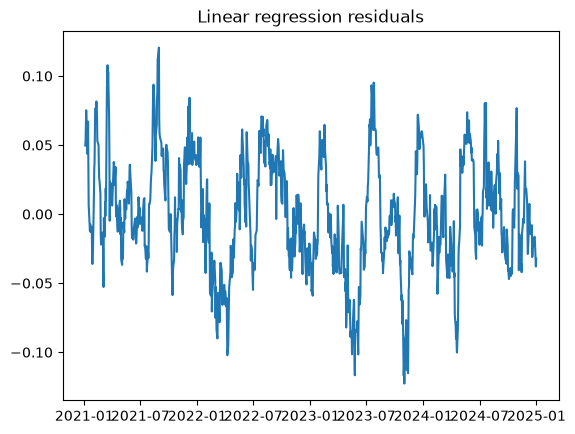

In [17]:
# Estimate the AMAT-NXPI OLS relationship
x_log = data_norm_train_logs["AMAT_Norm"]
y_log = data_norm_train_logs["NXPI_Norm"]

x_log_const = sm.add_constant(x_log)
modelo = sm.OLS(y_log, x_log_const).fit()
print(modelo.summary())

# Plot the residual spread
resid = modelo.resid
plt.figure()
plt.plot(resid)
plt.title("Linear regression residuals")
plt.show()

For AMAT–NXPI, the estimated OLS relationship is:

$$
\ln(P_{NXPI,t})=\alpha+\beta\ln(P_{AMAT,t})+\varepsilon_t
$$

Using normalized prices:

$$
\ln(P_{NXPI,t})=1.7689+0.6051\ln(P_{AMAT,t})+\varepsilon_t
$$

The in-sample coefficient of determination is $R^2=0.935$. The fitted cointegrating coefficient is approximately $\hat\beta=0.6051$. The residual is used as the spread; the high $R^2$ is descriptive and is not, by itself, evidence of cointegration.

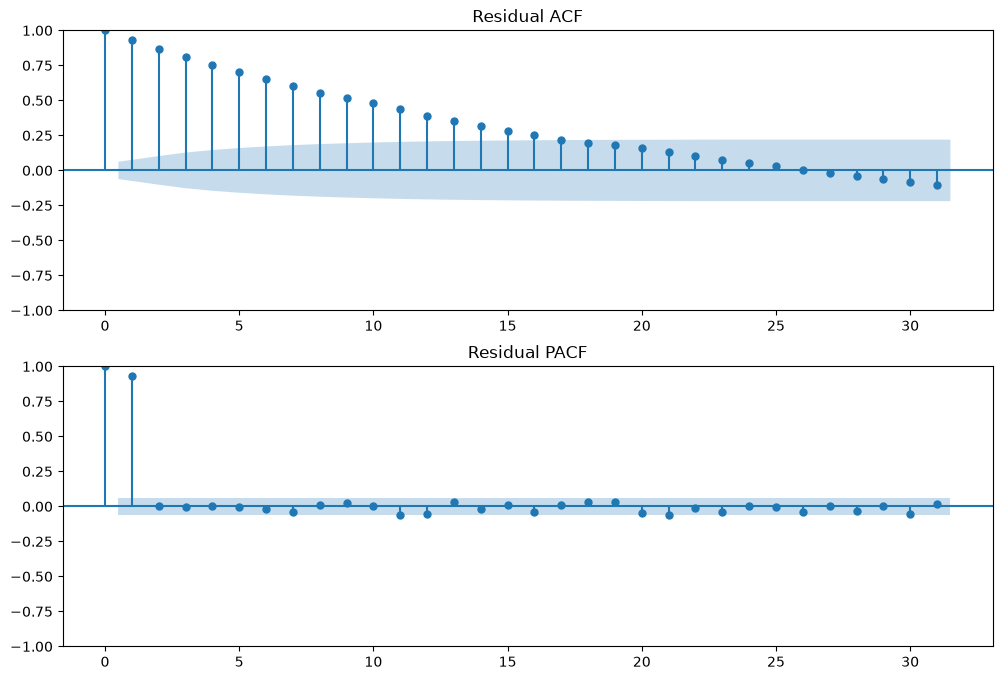

In [18]:
# Examine the residual ACF and PACF
fig, ax = plt.subplots(2, 1, figsize = (12,8))
plot_acf(resid, ax = ax[0], title = "Residual ACF")
plot_pacf(resid, ax = ax[1], title = "Residual PACF")
plt.show()

In [19]:
ar_modelo = ajustar_arima_optimo(resid, 3, 0, 3)
print(ar_modelo.summary())
print(f"\n Half-Life: {np.log(0.5) / np.log(ar_modelo.arparams[0])}")

ARIMA model (0,0,0) - BIC: -3529.6408780331326
ARIMA model (0,0,1) - BIC: -4429.583620896325
ARIMA model (0,0,2) - BIC: -4878.468972501631
ARIMA model (0,0,3) - BIC: -5115.712138609865
ARIMA model (1,0,0) - BIC: -5564.607408358597
ARIMA model (1,0,1) - BIC: -5557.7657261042705
ARIMA model (1,0,2) - BIC: -5550.859898404143
ARIMA model (1,0,3) - BIC: -5543.951728812192
ARIMA model (2,0,0) - BIC: -5557.771447454267
ARIMA model (2,0,1) - BIC: -5550.8656869621145
ARIMA model (2,0,2) - BIC: -5543.929853774801
ARIMA model (2,0,3) - BIC: -5537.064261575468
ARIMA model (3,0,0) - BIC: -5550.8591754603485
ARIMA model (3,0,1) - BIC: -5543.954077856588
ARIMA model (3,0,2) - BIC: -5537.057061478486
ARIMA model (3,0,3) - BIC: -5530.143428738315
Best ARIMA model (1, 0, 0) - BIC: -5564.6074
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1005
Model:                 ARIMA(1, 0, 0)   Log Likelihood   

In [20]:
# Examine rolling-window residual dynamics as an informal stability diagnostic
def ajustar_arima_optimo_ventana(serie, p_max, d_max, q_max, alpha = 0.05):
    serie = np.asarray(serie)
    d = 0
    serie_diff = serie.copy()

    # Use the ADF test to determine the differencing order
    while d <= d_max:
        adf_result  = adfuller(serie_diff)
        p_value = adf_result[1]

        if p_value < alpha:
            break

        serie_diff = np.diff(serie_diff)
        d += 1

    if d > d_max:
        raise ValueError("Stationarity was not achieved within the allowed d_max.")

    # Select ARIMA orders using BIC
    best_bic = np.inf
    best_model = None
    best_order = None

    for p in range(p_max + 1):
        for q in range(q_max + 1):
            try:
                model = ARIMA(serie, order=(p, d, q))
                model_fit = model.fit()

                if model_fit.bic < best_bic:
                    best_bic = model_fit.bic
                    best_model = model_fit
                    best_order = (p, d, q)

            except Exception as e:
                print(f"Error fitting ARIMA({p},{d},{q}): {e}")
                continue

    print(f"Best ARIMA model {best_order} - BIC: {best_bic:.4f}")
    return best_model


resultados_resid = []

for i in range(2021, 2024):
    fin = i + 1
    ventana = data_norm_train_logs.loc[f"{i}-01-01":f"{fin}-12-31"]

    x_t = ventana['AMAT_Norm']
    y_t = ventana['NXPI_Norm']

    modelo_ventana = sm.OLS(y_t, sm.add_constant(x_t)).fit()
    b = modelo_ventana.params["AMAT_Norm"]

    modelo_resid = modelo_ventana.resid
    ar_modelo_ventana = ajustar_arima_optimo_ventana(modelo_resid, 3, 0, 3)
    ar_modelo_ventana_params = ar_modelo_ventana.arparams[0]
    half_life = np.log(0.5) / np.log(ar_modelo_ventana_params)

    resultados_resid.append({
        "Inicio": i,
        "Final": fin,
        "Beta": b,
        "Phi": ar_modelo_ventana_params,
        "Half-Life": half_life
    })

resultados_dataframe = pd.DataFrame(resultados_resid)
resultados_dataframe.head()

Best ARIMA model (1, 0, 0) - BIC: -2747.0283
Best ARIMA model (1, 0, 0) - BIC: -2778.3111
Best ARIMA model (1, 0, 0) - BIC: -2806.7811


,Inicio,Final,Beta,Phi,Half-Life
0,2021,2022,0.608277,0.919102,8.216736
1,2022,2023,0.584792,0.944250,12.083287
2,2023,2024,0.646575,0.936465,10.559313


All three two-year AMAT–NXPI windows yield an AR(1) residual model, with estimated $\phi$ values from approximately $0.92$ to $0.94$ and half-lives of roughly $8$–$12$ sessions. The full training sample gives an estimated half-life of around $9.8$ trading sessions.

We now backtest the AMAT–NXPI strategy:

1. Construct the spread using parameters estimated only on 2021–2024 data.
2. Standardize the spread using the training-period residual mean and standard deviation.
3. Define entry, exit, stop-loss, and maximum-holding-period rules.
4. Form gross-exposure-normalized long/short positions.
5. Evaluate returns from January 2025 onward, including transaction and short-borrowing costs.
6. Report annualized returns, Sharpe/Sortino ratios, drawdown, and trade-level metrics.

The training-period equation is:

$$
\ln(P_{NXPI,t})=1.7689+0.6051\ln(P_{AMAT,t})+\varepsilon_t
$$

Thus, the out-of-sample spread is:

$$
\boxed{S_t=\ln(P_{NXPI,t})-\hat\alpha-\hat\beta\ln(P_{AMAT,t})}
$$

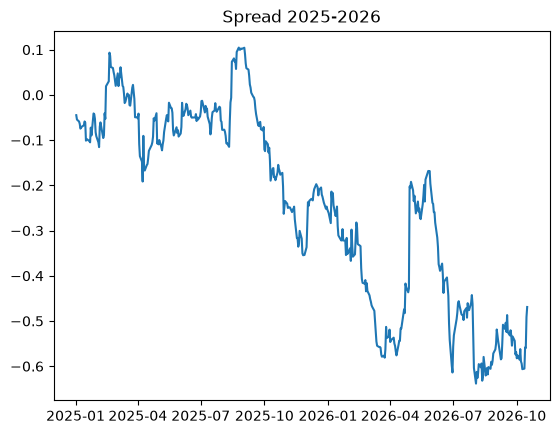

In [21]:
# Compute the out-of-sample spread starting in 2025
fecha_limite = datetime.datetime(2024, 12, 31)
data_norm_test = data_norm[data_norm.index > fecha_limite]

# Take log prices
data_norm_test_log = np.log(data_norm_test)
x_t = data_norm_test_log["AMAT_Norm"]
y_t = data_norm_test_log["NXPI_Norm"]

# Use parameters estimated in the training period
alpha = modelo.params["const"]
beta = modelo.params["AMAT_Norm"]

# Construct the spread from the training-period OLS coefficients
S_t = y_t - alpha - beta*x_t

# Plot the out-of-sample spread
plt.figure()
plt.plot(S_t)
plt.title("Spread 2025-2026")
plt.show()

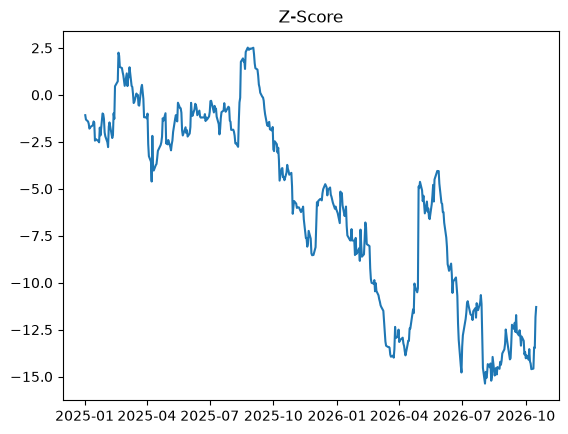

In [22]:
resid = modelo.resid
media = resid.mean()
desv = resid.std()

z = (S_t - media)/desv

plt.figure()
plt.plot(z)
plt.title("Z-Score")
plt.show()

The spread and Z-score trend markedly downward later in the out-of-sample period, especially in 2026. This pattern is **consistent with a possible deterioration in the previously estimated equilibrium relationship**, but the graph alone is **not a formal structural-break or cointegration test**.

We nonetheless evaluate a rule-based strategy to see how the trading and risk-management rules behave under these conditions.

| Event | Condition | Action |
|---|---|---|
| Enter long spread | Z-score crosses below $-2$, remaining above $-4$ | Buy NXPI, short AMAT |
| Enter short spread | Z-score crosses above $+2$, remaining below $+4$ | Short NXPI, buy AMAT |
| Take profit | Z-score reaches or crosses zero in the favorable direction | Close both legs |
| Stop-loss | Z-score reaches $\pm4$ against the position | Close both legs |
| Time exit | 30 sessions since the entry signal | Close both legs |

Additional backtesting rules:

- Allow only one spread position at a time.
- Enter on a threshold crossing rather than on every day the Z-score remains extreme.
- After a stop-loss, block new entries until $|Z_t|<1$.
- Generate signals at the close and execute at the **next session's close**; daily P&L begins on the following session.
- Keep training-period $\alpha$, $\beta$, residual mean, and residual standard deviation fixed throughout the backtest.
- Include simplified execution and short-borrowing costs when calculating net returns.

The stop-loss is triggered by a **statistical spread threshold**, not a guaranteed cap on monetary losses.

In [23]:
# Create preliminary threshold signals from the Z-score
condiciones = [
    z <= -2,
    z >= 2
]

valores = [1, -1]
señales = np.select(condiciones, valores, default = 0)

df_backtest = pd.DataFrame({
    "Spread": S_t,
    "Z-score": z,
    "Señal": señales
}, index=z.index)

df_backtest.head()

,Spread,Z-score,Señal
Date,,,
2025-01-02,-0.044864,-1.080298,0
2025-01-03,-0.054531,-1.313082,0
2025-01-06,-0.058822,-1.416413,0
2025-01-07,-0.063877,-1.538130,0
2025-01-08,-0.074591,-1.796122,0


In [24]:
posicion = 0
dias_posicion = 0
bloqueado = False

posiciones = []
motivos_salida = []

z_scores = df_backtest["Z-score"].to_numpy()

for i, z in enumerate(z_scores):

    z_anterior = z_scores[i-1] if i > 0 else np.nan
    motivo = None

    # Re-enable entries once Z returns near equilibrium
    if bloqueado and abs(z) < 1:
        bloqueado = False

    # ENTRY RULES
    if posicion == 0 and i > 0 and not bloqueado:

        # Long spread: buy NXPI and short AMAT
        if z_anterior > -2 and -4 < z <= -2:
            posicion = 1
            dias_posicion = 0

        # Short spread: short NXPI and buy AMAT
        elif z_anterior < 2 and 2 <= z < 4:
            posicion = -1
            dias_posicion = 0

    # MANAGE OPEN POSITIONS
    elif posicion != 0:

        dias_posicion += 1

        # Stop-loss triggered by an adverse spread deviation
        stop = (
            (posicion == 1 and z <= -4) or
            (posicion == -1 and z >= 4)
        )

        # Take profit when the spread Z-score crosses zero
        take_profit = (
            (posicion == 1 and z >= 0) or
            (posicion == -1 and z <= 0)
        )

        if stop:
            motivo = "Stop-Loss"
            posicion = 0
            bloqueado = True

        elif take_profit:
            motivo = "Take Profit"
            posicion = 0

        elif dias_posicion >= 30:
            motivo = "Time limit"
            posicion = 0

        if posicion == 0:
            dias_posicion = 0

    posiciones.append(posicion)
    motivos_salida.append(motivo)

# Save positions implied by end-of-day signals
df_backtest["Posicion_senal"] = posiciones

# Apply a one-session delay for next-close execution
df_backtest["Posicion"] = (
    df_backtest["Posicion_senal"]
    .shift(1)
    .fillna(0)
    .astype(int)
)

df_backtest["Motivo_salida"] = motivos_salida
df_backtest[
    df_backtest["Motivo_salida"].notna()
][["Z-score", "Posicion_senal", "Motivo_salida"]]

,Z-score,Posicion_senal,Motivo_salida
Date,,,
2025-02-14,0.460959,0,Take Profit
2025-03-13,-0.434155,0,Take Profit
2025-04-08,-4.613028,0,Stop-Loss
2025-06-11,-0.535753,0,Time limit
2025-08-15,1.764855,0,Take Profit
2025-09-15,-0.102624,0,Take Profit
2025-10-10,-4.564835,0,Stop-Loss


After defining entry and exit signals, we estimate strategy returns for two directions:

- **Long spread:** buy NXPI and short AMAT.
- **Short spread:** short NXPI and buy AMAT.

With $\hat\beta\approx0.6051$, the approximate daily return per unit of *gross exposure* is:

$$
\boxed{R_{p,t}=\frac{\text{EffectivePosition}_t}{1+|\beta|}\left(R_{NXPI,t}-\beta R_{AMAT,t}\right)}
$$

Returns are calculated from adjusted stock prices. The weights sum to one in absolute value, but the portfolio is **not necessarily dollar-neutral** when $\beta\ne1$.

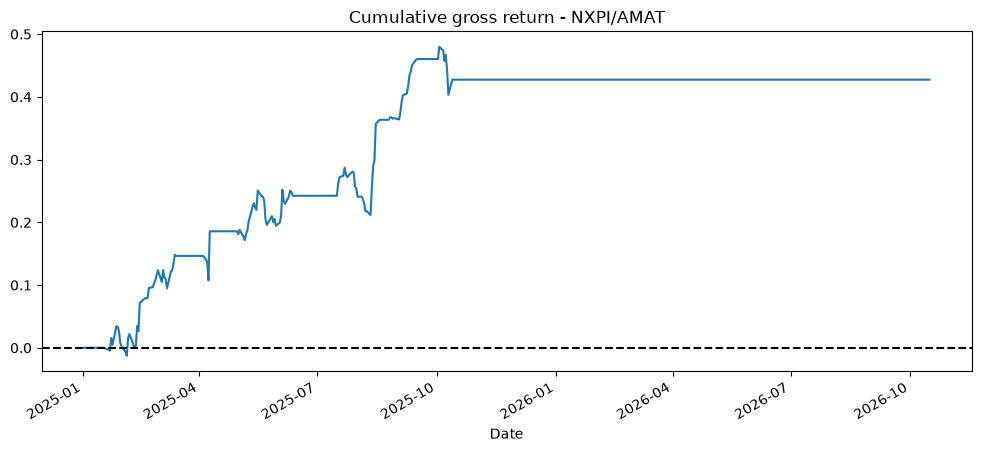

In [25]:
retornos = np.expm1(
    data_norm_test_log[["NXPI_Norm", "AMAT_Norm"]].diff()
)

df_backtest["R_NXPI"] = retornos["NXPI_Norm"]
df_backtest["R_AMAT"] = retornos["AMAT_Norm"]

df_backtest["Posicion_efectiva"] = (
    df_backtest["Posicion"].shift().fillna(0)
)

df_backtest["Rentabilidad"] = (
    df_backtest["Posicion_efectiva"] *
    (df_backtest["R_NXPI"] - beta * df_backtest["R_AMAT"]) /
    (1 + abs(beta))
).fillna(0)

# Compound daily gross returns starting from unit capital
df_backtest["Rent_Acumulada"] = (
    (1 + df_backtest["Rentabilidad"]).cumprod() - 1
)

df_backtest["Rent_Acumulada"].plot(figsize = (12, 5))
plt.title("Cumulative gross return - NXPI/AMAT")
plt.axhline(0, color = "black", linestyle = "--")
plt.show()

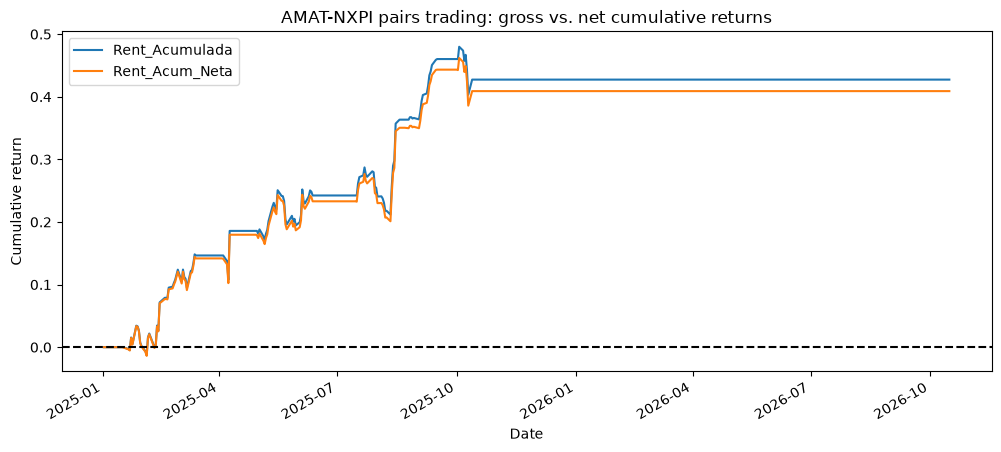

In [26]:
# Transaction and borrow-cost assumptions
coste_operacion = 0.0005
coste_corto_anual = 0.03
sesiones = 252

# Gross-exposure-normalized portfolio weights
peso_nxpi = 1 / (1 + abs(beta))
peso_amat = abs(beta) / (1 + abs(beta))

# Trading costs on entry and exit
# Posicion is the position after execution at the session close
pos = df_backtest["Posicion"].fillna(0)

df_backtest["Rotacion"] = pos.diff().abs().fillna(pos.abs())

df_backtest["Coste_Operacion"] = (
    df_backtest["Rotacion"] * coste_operacion
)

# Daily borrowing charge on the short leg
pos_efectiva = df_backtest["Posicion_efectiva"]

df_backtest["Peso_Corto"] = np.select(
    [pos_efectiva == 1, pos_efectiva == -1],
    [peso_amat, peso_nxpi],
    default=0.0
)

df_backtest["Coste_Corto"] = (
    df_backtest["Peso_Corto"] * coste_corto_anual / sesiones
)

# Approximate net daily returns
df_backtest["Rentabilidad_Neta"] = (
    df_backtest["Rentabilidad"]
    - df_backtest["Coste_Operacion"]
    - df_backtest["Coste_Corto"]
)

df_backtest["Rent_Acum_Neta"] = (
    (1 + df_backtest["Rentabilidad_Neta"]).cumprod() - 1
)

df_backtest[
    ["Rent_Acumulada", "Rent_Acum_Neta"]
].plot(figsize=(12, 5))

plt.title("AMAT-NXPI pairs trading: gross vs. net cumulative returns")
plt.ylabel("Cumulative return")
plt.axhline(0, color="black", linestyle="--")
plt.show()

In [27]:
# Calculate out-of-sample performance metrics
r = df_backtest["Rentabilidad_Neta"].fillna(0)
r_bruta = df_backtest["Rentabilidad"].fillna(0)
pos = df_backtest["Posicion_efectiva"].fillna(0)

# Returns
rent_total = (1 + r).prod() - 1
rent_bruta = (1 + r_bruta).prod() - 1
cagr = (1 + rent_total)**(252 / len(r)) - 1

# Risk
vol_anual = r.std() * np.sqrt(252)
sharpe = r.mean() / r.std() * np.sqrt(252)

downside = np.sqrt(np.mean(np.minimum(r, 0)**2))
sortino = r.mean() / downside * np.sqrt(252) if downside > 0 else np.nan

# Drawdown
capital = (1 + r).cumprod()
max_historico = capital.cummax().clip(lower=1)
drawdown = capital / max_historico - 1

max_drawdown = drawdown.min()
calmar = cagr / abs(max_drawdown) if max_drawdown < 0 else np.nan

# Trading activity
dias_con_resultado = r[r != 0]
win_rate_diario = (dias_con_resultado > 0).mean()

exposicion = (pos != 0).mean()

entradas = (pos != 0) & (pos != pos.shift(fill_value=0))
n_operaciones = entradas.sum()

# Costs
costes_operacion = df_backtest["Coste_Operacion"].sum()
costes_corto = df_backtest["Coste_Corto"].sum()

# Print results
print(f"Total net return: {rent_total:.2%}")
print(f"Total gross return: {rent_bruta:.2%}")
print(f"CAGR: {cagr:.2%}")
print(f"Annualized volatility: {vol_anual:.2%}")
print(f"Sharpe Ratio: {sharpe:.4f}")
print(f"Sortino Ratio: {sortino:.4f}")
print(f"Maximum Drawdown: {max_drawdown:.2%}")
print(f"Calmar Ratio: {calmar:.4f}")
print(f"Positive days (nonzero returns): {win_rate_diario:.2%}")
print(f"Time in market: {exposicion:.2%}")
print(f"Trades initiated: {n_operaciones}")
print(f"Total transaction costs (sum): {costes_operacion:.2%}")
print(f"Total short-borrow costs (sum): {costes_corto:.2%}")

Total net return: 40.90%
Total gross return: 42.74%
CAGR: 21.22%
Annualized volatility: 11.93%
Sharpe Ratio: 1.6722
Sortino Ratio: 3.5846
Maximum Drawdown: -5.92%
Calmar Ratio: 3.5863
Positive days (nonzero returns): 52.07%
Time in market: 25.39%
Trades initiated: 7
Total transaction costs (sum): 0.70%
Total short-borrow costs (sum): 0.60%


In [28]:
pos = df_backtest["Posicion"].fillna(0)
prev = pos.shift(fill_value=0)

entrada = (pos != 0) & (pos != prev)
salida = (pos == 0) & (prev != 0)

n_op = entrada.cumsum()

id_op = n_op.where(
    (n_op > 0) & ((pos != 0) | salida)
)

aux = df_backtest.assign(Operacion=id_op)

resultados = []

for _, grupo in aux.dropna(subset=["Operacion"]).groupby("Operacion"):

    dias_activos = grupo[grupo["Posicion_efectiva"] != 0]

    resultados.append({
        "Entrada": grupo.index[0],
        "Salida": grupo.index[-1],
        "Dias": len(dias_activos),
        "Rentabilidad_Neta": (
            1 + grupo["Rentabilidad_Neta"].fillna(0)
        ).prod() - 1
    })

df_operaciones = pd.DataFrame(resultados)


r_op = df_operaciones["Rentabilidad_Neta"]

# Win Rate
win_rate = (r_op > 0).mean()

# Profit Factor
beneficios = r_op[r_op > 0].sum()
perdidas = abs(r_op[r_op < 0].sum())

profit_factor = beneficios / perdidas if perdidas > 0 else np.inf

# Average winning and losing trade returns
ganancia_media = r_op[r_op > 0].mean()
perdida_media = r_op[r_op < 0].mean()

# Average trade duration
duracion_media = df_operaciones["Dias"].mean()

print(f"Win Rate: {win_rate:.2%}")
print(f"Profit Factor: {profit_factor:.4f}")
print(f"Average winning trade: {ganancia_media:.2%}")
print(f"Average losing trade: {perdida_media:.2%}")
print(f"Average holding period: {duracion_media:.2f} días")

rent_reconstruida = (1 + r_op).prod() - 1

print(f"Reconstructed return: {rent_reconstruida:.2%}")
print(f"Backtest return: {(1 + df_backtest['Rentabilidad_Neta'].fillna(0)).prod() - 1:.2%}")

Win Rate: 85.71%
Profit Factor: 15.9732
Average winning trade: 6.33%
Average losing trade: -2.38%
Average holding period: 16.29 días
Reconstructed return: 40.90%
Backtest return: 40.90%


In [29]:
# Inspect the final backtest sessions
display(df_backtest[[
    "Posicion_senal",
    "Posicion",
    "Posicion_efectiva",
    "Rotacion",
    "Coste_Operacion"
]].tail(5))

# Confirm that there is no open position at the end
pos_final = df_backtest["Posicion"].iloc[-1]

if pos_final == 0:
    print("No positions remain open.")
else:
    print(f"Open position at sample end: {pos_final}")
    print(f"Estimated outstanding exit cost: {abs(pos_final) * coste_operacion:.4%}")

,Posicion_senal,Posicion,Posicion_efectiva,Rotacion,Coste_Operacion
Date,,,,,
2026-10-12,0,0,0.0,0.0,0.0
2026-10-13,0,0,0.0,0.0,0.0
2026-10-14,0,0,0.0,0.0,0.0
2026-10-15,0,0,0.0,0.0,0.0
2026-10-16,0,0,0.0,0.0,0.0


No positions remain open.


# Conclusions

## Econometric findings

This project develops a semiconductor-sector pairs-trading strategy using Engle–Granger cointegration tests and systematic spread mean-reversion rules. The 2021–2024 in-sample period is used to examine unit roots, select candidate pairs, estimate hedge coefficients, and calibrate the spread's Z-score.

Of the 276 pairs formed from stocks compatible with $I(1)$, AMAT–NXPI and LRCX–NXPI pass the Bonferroni-adjusted full-sample screen. AMAT–NXPI is selected because its cointegration test is significant across all three examined two-year windows. Its estimated training-period relationship is:

$$
\ln(P_{NXPI,t})=1.7689+0.6051\ln(P_{AMAT,t})+\varepsilon_t
$$

An AR(1) fitted to the full-sample residuals suggests a mean-reversion half-life of approximately 9.8 trading sessions.

## Out-of-sample performance

The out-of-sample backtest starts in January 2025. The following figures come from the notebook's saved run (through **16 October 2026**) and include simplified trading and short-borrowing costs.

| Metric | Result |
|---|---:|
| Total net return | **40.90%** |
| Annualized return (CAGR) | **21.22%** |
| Annualized volatility | **11.93%** |
| Sharpe ratio (zero risk-free rate) | **1.67** |
| Sortino ratio | **3.58** |
| Maximum drawdown | **-5.92%** |
| Calmar ratio | **3.59** |
| Completed trades | **7** |
| Trade win rate | **85.71%** (6/7) |
| Profit factor | **15.97** |
| Gross-exposure time | **25.39%** |

The observed return and risk-adjusted metrics are attractive, but **only seven completed trades** are available. Consequently, the figures should not be treated as strong evidence of repeatable live-trading performance.

## Regime stability and risk management

The strategy records a stop-loss exit in October 2025 and makes no subsequent entries in the saved sample. The out-of-sample spread also exhibits a sustained negative deviation. These observations suggest that the estimated equilibrium relationship **may** have weakened. However, they do **not** formally establish a structural break or prove that cointegration disappeared.

The strategy uses threshold-triggered stop-losses, a 30-session maximum holding period, and a lockout after a stop-loss until the Z-score returns close to equilibrium. Orders are assumed to execute at the next session's close after signal generation, while the hedge coefficient and Z-score calibration remain fixed at their in-sample estimates. The backtest ends without an open position, and trade-level compounded returns reconcile to the daily backtest result.

## Limitations and takeaways

- Only seven trades limit statistical confidence, especially for win rate and profit factor.
- Execution and borrowing costs are simplified; slippage, taxes, financing constraints, and hard-to-borrow availability are not modeled.
- Z-score stop-losses do not bound realized monetary losses, especially when prices gap or execution is delayed.
- In-sample estimates are held fixed throughout the out-of-sample period and may become stale if market relationships change.
- Adjusted historical data are downloaded dynamically, so rerunning the notebook without a frozen data snapshot may produce different figures.
- Multiple comparisons are addressed in the initial cointegration screen, but the full research-and-selection process still involves model-selection uncertainty.

**Overall:** Historical cointegration is a useful starting point for pairs trading, not a guarantee of a stable tradable relationship. The exercise highlights the importance of screening, careful execution assumptions, risk management, and genuinely out-of-sample evaluation.